# 5. Estacionariedad, memoria y varianza

ADF contrasta una raíz unitaria; KPSS contrasta estacionariedad alrededor de una constante. Se usan de forma conjunta y con las cuatro interpretaciones posibles. Las pruebas se ejecutan sobre medias diarias para separar el diagnóstico de cambios lentos del ciclo intradiario. Su interpretación se circunscribe a la frecuencia diaria analizada.

ADF selecciona por AIC hasta 30 rezagos y KPSS usa rezagos automáticos. Se informan los límites de los p-valores tabulados de KPSS. ACF/PACF se calculan sobre log1p horario, con bandas aproximadas que no representan pruebas independientes para cientos de rezagos. ARCH y Ljung–Box usan residuos de un AR(7) de diagnóstico ajustado en entrenamiento; BDS usa sus últimos mil residuos. El AR(7) se utiliza como modelo auxiliar para el diagnóstico de residuos.

Documentación primaria: [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html), [BDS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.bds.html).


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from statsmodels.tsa.ar_model import AutoReg
from IPython.display import Markdown, display
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf, bds
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

In [2]:
TARGET = 'precio_bolsa_cop_kwh'
RESULTS = ROOT / 'results'
SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
TIME = 'timestamp_start_colombia'
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [4]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [5]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [6]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [7]:
def train_daily():
    frame = load_numeric()
    return (frame, frame[TARGET].resample('D').mean())

In [8]:
frame, daily = train_daily()
rows = []
candidates = {'nivel_diario': daily, 'log1p_diario': np.log1p(daily), 'diferencia_log1p': np.log1p(daily).diff().dropna()}
for name, x in candidates.items():
    a = adfuller(x, maxlag=30, regression='c', autolag='AIC', result_object=False)
    with warnings.catch_warnings(record=True) as notes:
        warnings.simplefilter('always')
        k = kpss(x, regression='c', nlags='auto')
    adf_reject = a[1] < 0.05
    kpss_reject = k[1] < 0.05
    outcomes = {(True, False): 'Compatible con estacionariedad', (False, True): 'Compatible con raíz unitaria/no estacionariedad', (True, True): 'Conflicto: rupturas/heterocedasticidad u otra alternativa', (False, False): 'Inconcluso: ambas H0 no rechazadas'}
    kp = '<0.01' if k[1] <= 0.01 else '>0.10' if k[1] >= 0.1 else f'{k[1]:.6g}'
    rows.append(dict(serie=name, n=len(x), adf_estadistico=a[0], adf_p=a[1], adf_rezagos=a[2], kpss_estadistico=k[0], kpss_p_acotado=kp, kpss_rezagos=k[2], lectura_conjunta=outcomes[adf_reject, kpss_reject]))
table(pd.DataFrame(rows).set_index('serie'), 'adf_kpss_train')

,n,adf_estadistico,adf_p,adf_rezagos,kpss_estadistico,kpss_p_acotado,kpss_rezagos,lectura_conjunta
serie,,,,,,,,
nivel_diario,6575,-5.2708,6.2921e-06,29,3.863,<0.01,51,Conflicto: rupturas/heterocedasticidad u otra ...
log1p_diario,6575,-3.8335,0.0025828,28,7.3946,<0.01,51,Conflicto: rupturas/heterocedasticidad u otra ...
diferencia_log1p,6574,-17.653,3.7109e-30,27,0.0092604,>0.10,23,Compatible con estacionariedad


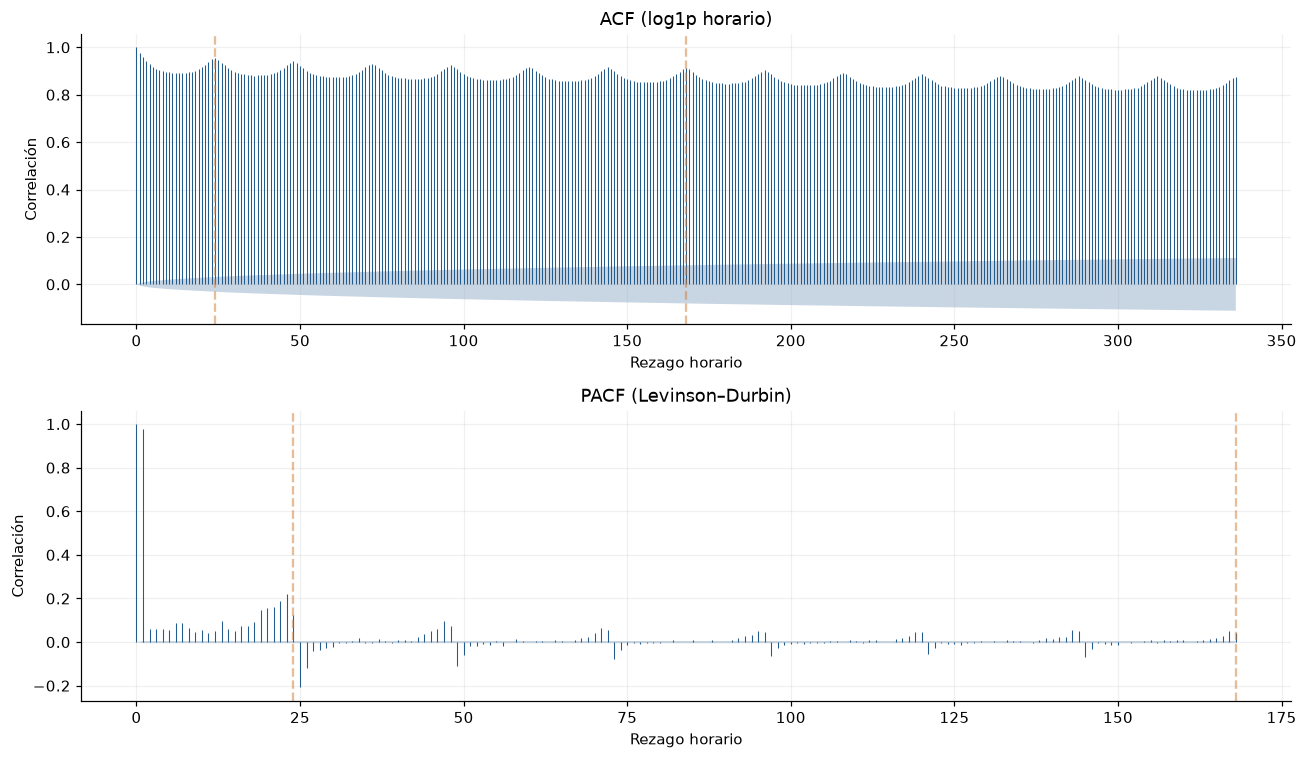

In [9]:
y = np.log1p(frame[TARGET].to_numpy())
ac, ci = acf(y, nlags=336, fft=True, alpha=0.05, result_object=False)
pc, pci = pacf(y, nlags=168, method='ldbiased', alpha=0.05)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, vals, bands, title in [(axes[0], ac, ci, 'ACF (log1p horario)'), (axes[1], pc, pci, 'PACF (Levinson–Durbin)')]:
    lags = np.arange(len(vals))
    ax.vlines(lags, 0, vals, lw=0.7)
    ax.fill_between(lags, bands[:, 0] - vals, bands[:, 1] - vals, alpha=0.25)
    for lag in [24, 168]:
        ax.axvline(lag, color='#d17a32', alpha=0.5, ls='--')
    ax.set(xlabel='Rezago horario', ylabel='Correlación', title=title)
figure(fig, 'acf_pacf_train')

In [10]:
model = AutoReg(np.log1p(daily.to_numpy()), lags=7).fit()
resid = model.resid
arch = het_arch(resid, nlags=14, result_object=False)
bstat, bp = bds(resid[-1000:], max_dim=3, distance=1.5)
diagnostics = pd.DataFrame({'estadístico': [arch[0], *np.atleast_1d(bstat)], 'p': [arch[1], *np.atleast_1d(bp)]}, index=['ARCH LM (14)', 'BDS dimensión 2', 'BDS dimensión 3'])
table(diagnostics, 'dependencia_no_lineal_train')

,estadístico,p
ARCH LM (14),594.97,6.2455e-118
BDS dimensión 2,11.221,3.199e-29
BDS dimensión 3,12.88,5.8455e-38


In [11]:
table(acorr_ljungbox(resid, lags=[7, 14, 30], return_df=True), 'ljung_box_ar7_train')

,lb_stat,lb_pvalue
7,126.91,2.7831e-24
14,366.47,1.4345e-69
30,700.67,3.5553e-128


In [12]:
decision('La lectura conjunta ADF/KPSS determina qué transformaciones comparar; no diferenciar automáticamente por un único p-valor.', 'Memoria estacional y varianza variable justifican comparar arquitecturas y pérdidas robustas con referencias lineales fuertes.', 'Errores dependientes requieren bootstrap por bloques o inferencia temporal; las horas y semillas no son observaciones independientes equivalentes.', 'BDS rechaza independencia bajo varias alternativas, incluida heterocedasticidad: no demuestra por sí solo no linealidad de la media ni utilidad del texto. Pruebas exploratorias y sensibles a rupturas.')

### Implicaciones del análisis

- **Preprocesamiento:** La lectura conjunta ADF/KPSS determina qué transformaciones comparar; no diferenciar automáticamente por un único p-valor.
- **Arquitectura:** Memoria estacional y varianza variable justifican comparar arquitecturas y pérdidas robustas con referencias lineales fuertes.
- **Validación:** Errores dependientes requieren bootstrap por bloques o inferencia temporal; las horas y semillas no son observaciones independientes equivalentes.
- **Riesgos:** BDS rechaza independencia bajo varias alternativas, incluida heterocedasticidad: no demuestra por sí solo no linealidad de la media ni utilidad del texto. Pruebas exploratorias y sensibles a rupturas.